# Task 5 · Sales Prediction Using Python

Predict product sales from advertising spend on TV, radio, and newspapers. This is the third completed task in the data science track.

The table is the classic advertising dataset: **200 products**, with spend and sales recorded in thousands. The columns are TV, Radio, Newspaper, and Sales.


## 1. Setup


In [1]:
from pathlib import Path

import numpy as np
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

DATA_PATH = Path("data") / "Advertising.csv"
FEATURES = ["TV", "Radio", "Newspaper"]
TARGET = "Sales"


## 2. Load and inspect

The file's first column is a row number, not a feature. It is dropped before any statistics or plots.


In [2]:
raw = pd.read_csv(DATA_PATH)
df = raw.drop(columns=["Unnamed: 0"])

print("Shape:", df.shape)
print()
print("Data types:")
print(df.dtypes)
print()
print("Missing values:")
print(df.isnull().sum())
df.head()


Shape: (200, 4)

Data types:
TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

Missing values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [3]:
df.describe()


,TV,Radio,Newspaper,Sales
count,200.000,200.000,200.000,200.000
mean,147.042,23.264,30.554,14.023
std,85.854,14.847,21.779,5.217
min,0.700,0.000,0.300,1.600
25%,74.375,9.975,12.750,10.375
50%,149.750,22.900,25.750,12.900
75%,218.825,36.525,45.100,17.400
max,296.400,49.600,114.000,27.000


There are **200 rows and 4 columns**, all numeric, and **no missing values**. TV budgets are the largest (mean about 147, maximum 296). Radio budgets are smaller (mean about 23). Newspaper sits in between (mean about 31) and has a long upper tail, with a maximum of 114. Sales range from 1.6 to 27.0, with a mean of about 14.0. Units are thousands of dollars for spend and thousands of units for sales.


## 3. How the columns move together

The pairplot shows every pair of columns. The heatmap puts a correlation on each pair. The three scatter plots isolate each channel against sales.


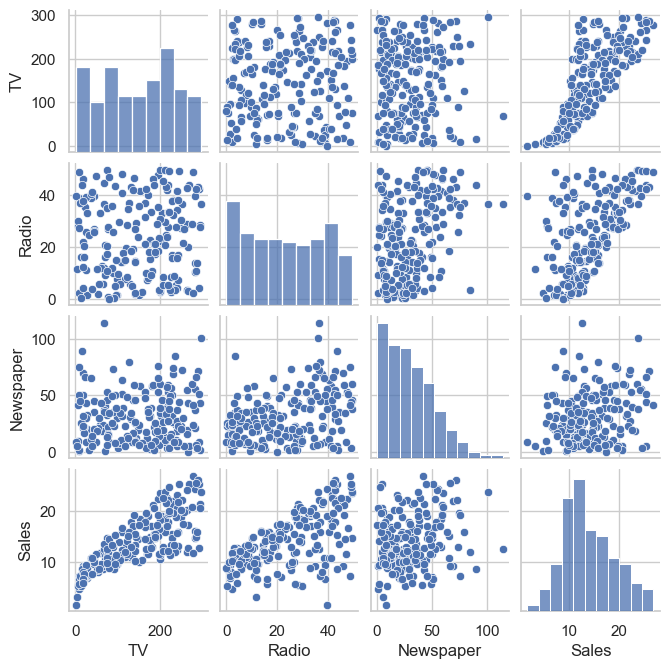

In [4]:
sns.pairplot(df, height=1.7)
plt.show()


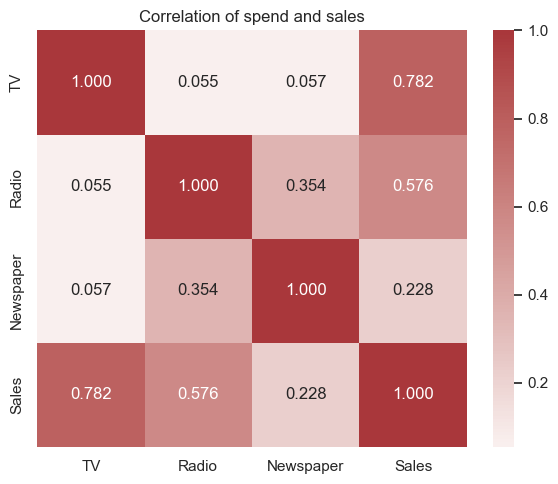

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(df.corr(), annot=True, fmt=".3f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation of spend and sales")
fig.tight_layout()
plt.show()


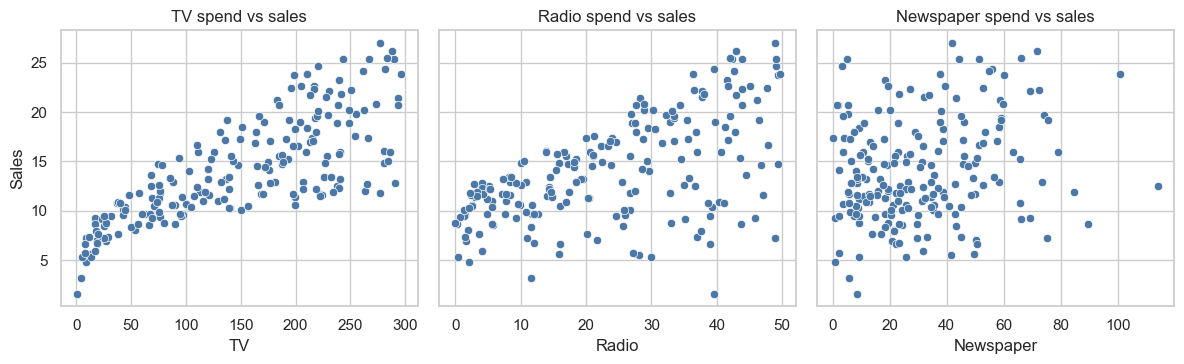

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, feature in zip(axes, FEATURES):
    sns.scatterplot(data=df, x=feature, y=TARGET, ax=ax, color="#4C78A8")
    ax.set_title(f"{feature} spend vs sales")
fig.tight_layout()
plt.show()


TV has the strongest linear link with sales (**correlation 0.782**). The TV scatter rises steadily: products with almost no TV spend cluster near the bottom of the sales axis, and the highest TV budgets sit near the top.

Radio is the second link (**0.576**). The cloud slopes upward, with more vertical scatter than the TV plot.

Newspaper is weak (**0.228**). High newspaper budgets appear at both low and high sales, so newspaper spend on its own does not sort the products. Newspaper is moderately related to radio (0.354), which is a reason not to read the raw newspaper correlation as a real sales effect. TV and radio are almost unrelated to each other (0.055), so they are two separate signals.


## 4. Train/test split and models

The split is 80/20 (`random_state=42`): 160 products to fit, 40 to test.

Two regressors are trained. Linear regression assumes sales rise by a fixed amount for each extra unit of spend. A random forest of 200 trees can follow a bend or a combination of channels, for example TV mattering more once radio spend is already high.


In [7]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)


Training rows: 160
Test rows: 40


## 5. Evaluation

- **MAE**: average absolute miss, in the same units as sales.
- **RMSE**: like MAE, but large misses count more.
- **R²**: share of test-set sales variation the predictions capture. 1 would be a perfect fit.


In [8]:
score_rows = []
for name, predicted in predictions.items():
    score_rows.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, predicted),
        "RMSE": root_mean_squared_error(y_test, predicted),
        "R2": r2_score(y_test, predicted),
    })
scores = pd.DataFrame(score_rows).set_index("model")
scores


,MAE,RMSE,R2
model,,,
Linear Regression,1.461,1.782,0.899
Random Forest,0.629,0.757,0.982


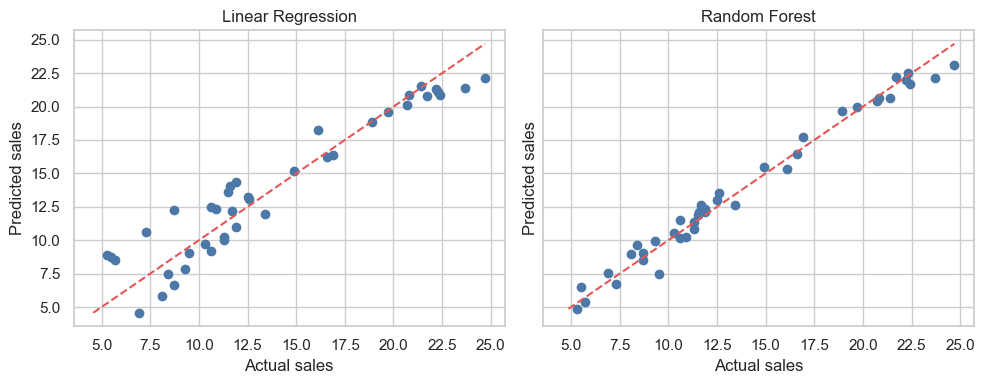

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, name in zip(axes, predictions):
    predicted = predictions[name]
    ax.scatter(y_test, predicted, color="#4C78A8")
    lower = min(y_test.min(), predicted.min())
    upper = max(y_test.max(), predicted.max())
    ax.plot([lower, upper], [lower, upper], color="#E45756", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Actual sales")
    ax.set_ylabel("Predicted sales")
fig.tight_layout()
plt.show()


## 6. Which channel the linear model uses

Coefficients are the change in sales for one extra unit of that channel's spend, holding the other two channels fixed. Because TV budgets are much larger than radio budgets, a smaller TV coefficient can still move sales more on a typical product.


In [10]:
linear_model = models["Linear Regression"]
coefficients = pd.Series(linear_model.coef_, index=FEATURES, name="coefficient")
average_contribution = coefficients * df[FEATURES].mean()
average_contribution.name = "contribution_at_mean_spend"
channel_view = pd.concat([coefficients, average_contribution], axis=1)

importances = pd.Series(
    models["Random Forest"].feature_importances_,
    index=FEATURES,
    name="random_forest_importance",
)
channel_view = channel_view.join(importances)
print("Linear regression intercept:", round(linear_model.intercept_, 3))
channel_view


Linear regression intercept: 2.979


,coefficient,contribution_at_mean_spend,random_forest_importance
TV,0.045,6.577,0.625
Radio,0.189,4.401,0.362
Newspaper,0.003,0.084,0.013


## 7. Best model

**Random forest is the better predictor on the held-out 40 products.**

| Model | MAE | RMSE | R² |
| --- | ---: | ---: | ---: |
| Random forest | 0.629 | 0.757 | 0.982 |
| Linear regression | 1.461 | 1.782 | 0.899 |

The forest cuts the typical absolute error from about 1.46 sales units to about 0.63, and it leaves less of the test-set variation unexplained (R² 0.982 against 0.899). The predicted-versus-actual plots show the same thing: forest points sit closer to the diagonal, including at the low and high ends where a straight line bends away from the data.

The channel results agree across both models. TV is the main driver (correlation 0.782, forest importance 0.625). Radio is second (correlation 0.576, importance 0.362). Newspaper is negligible once the other two are known: its linear coefficient is about 0.003, and its forest importance is 0.013.

The linear coefficients need the scale caveat. Radio's coefficient (about 0.189) is larger than TV's (about 0.045) because one unit of radio spend is a much bigger step relative to a typical radio budget. At the average budget, TV's contribution to predicted sales is still larger than radio's. Newspaper's contribution at the average budget is near zero.

Linear regression remains the model to quote when the question is "how many extra sales per thousand dollars on this channel." For predicting the sales number itself, the random forest is the one that fits this test set.


## 8. Residual plot for the best model

The best model on the test set is the random forest. A residual is actual sales minus predicted sales. Random errors scatter around zero with no curve and no widening band. A curve, or a fan that opens as the prediction grows, means the model is systematically off.


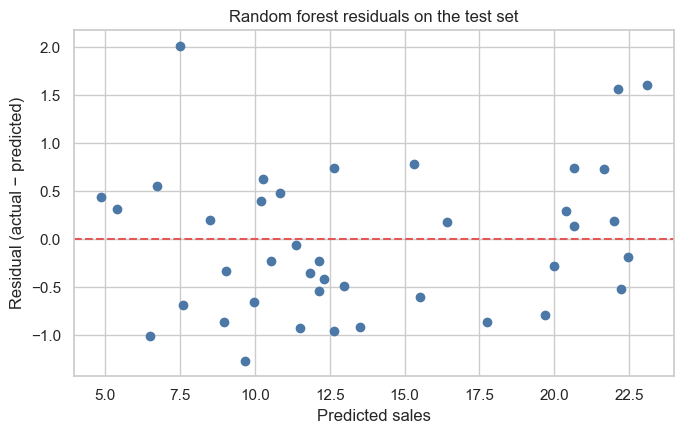

Mean residual: -0.028
Residual standard deviation: 0.757


In [11]:
best_name = "Random Forest"
best_predicted = predictions[best_name]
residuals = y_test.to_numpy() - best_predicted

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(best_predicted, residuals, color="#4C78A8")
ax.axhline(0, color="#E45756", linestyle="--")
ax.set_xlabel("Predicted sales")
ax.set_ylabel("Residual (actual − predicted)")
ax.set_title("Random forest residuals on the test set")
fig.tight_layout()
plt.show()

print("Mean residual:", round(float(residuals.mean()), 3))
print("Residual standard deviation:", round(float(residuals.std()), 3))


The residuals sit around zero. Their mean on the 40 test products is about **−0.03** sales units, so the forest is not consistently high or low. The spread is about **0.77**, in line with the RMSE. There is no clear curve and no strong fan: absolute error is about **0.61** on the cheaper half of the predictions and about **0.65** on the dearer half. The misses look mostly random, with a few larger ones that are not lined up with the predicted sales.
